# Chapter 10 — Clustering Techniques

**Reference:** *scikit-learn Cookbook, Third Edition* — John Sukup

This notebook compares K-means, agglomerative clustering, and DBSCAN on synthetic data.

## 1. Theory
Clustering groups observations without target labels. **K-means** assigns points to centroids and requires a cluster count. **Agglomerative clustering** merges groups hierarchically. **DBSCAN** identifies dense regions and may label observations as noise. Scaling is important for distance-based methods.

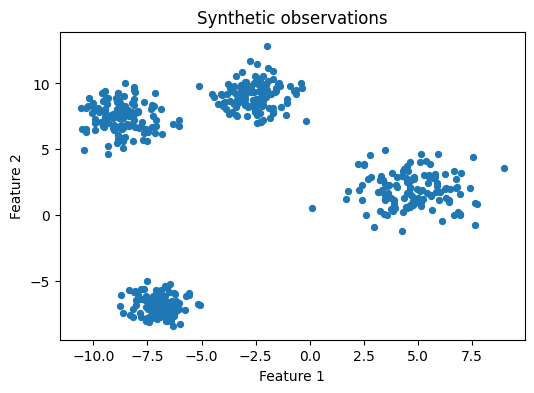

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RANDOM_STATE = 42

from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
X, y_true = make_blobs(n_samples=500, centers=4, cluster_std=[1.0,1.4,.7,1.1], random_state=RANDOM_STATE)
X_scaled = StandardScaler().fit_transform(X)
plt.figure(figsize=(6,4)); plt.scatter(X[:,0],X[:,1],s=18)
plt.title("Synthetic observations"); plt.xlabel("Feature 1"); plt.ylabel("Feature 2"); plt.show()


## 2. K-means and selecting k

Silhouette: 0.784
Adjusted Rand index: 1.0


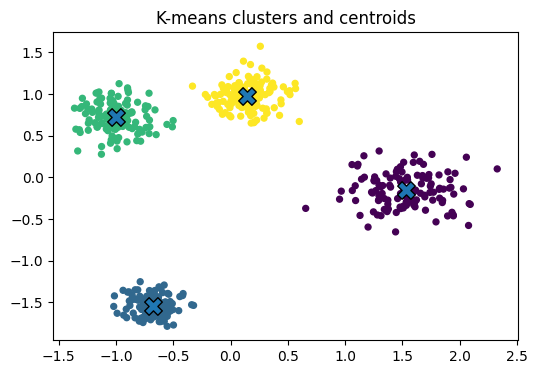

,Inertia,Silhouette
k,,
2,525.223,0.563
3,119.628,0.742
4,33.454,0.784
5,27.279,0.682
6,24.409,0.578
7,22.513,0.570


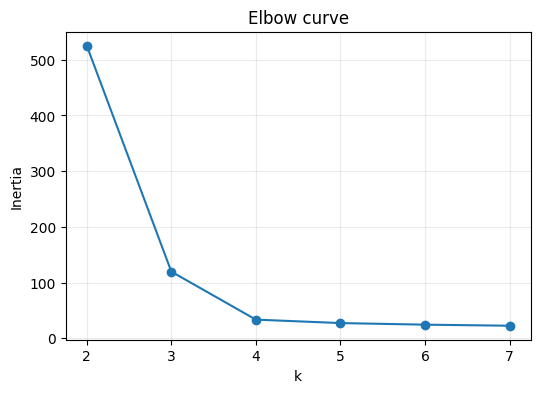

In [2]:

km=KMeans(n_clusters=4,n_init=10,random_state=RANDOM_STATE)
labels_km=km.fit_predict(X_scaled)
print("Silhouette:",round(silhouette_score(X_scaled,labels_km),3))
print("Adjusted Rand index:",round(adjusted_rand_score(y_true,labels_km),3))
plt.figure(figsize=(6,4)); plt.scatter(X_scaled[:,0],X_scaled[:,1],c=labels_km,s=18,cmap="viridis")
plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],marker="X",s=160,edgecolor="black")
plt.title("K-means clusters and centroids"); plt.show()
rows=[]
for k in range(2,8):
    m=KMeans(n_clusters=k,n_init=10,random_state=RANDOM_STATE).fit(X_scaled)
    rows.append({"k":k,"Inertia":m.inertia_,"Silhouette":silhouette_score(X_scaled,m.labels_)})
res=pd.DataFrame(rows); display(res.set_index("k").round(3))
plt.figure(figsize=(6,4)); plt.plot(res.k,res.Inertia,marker="o")
plt.xlabel("k"); plt.ylabel("Inertia"); plt.title("Elbow curve"); plt.grid(alpha=.25); plt.show()


## 3. Agglomerative clustering and DBSCAN

Agglomerative silhouette: 0.784
DBSCAN labels (-1 means noise): [-1  0  1  2  3]


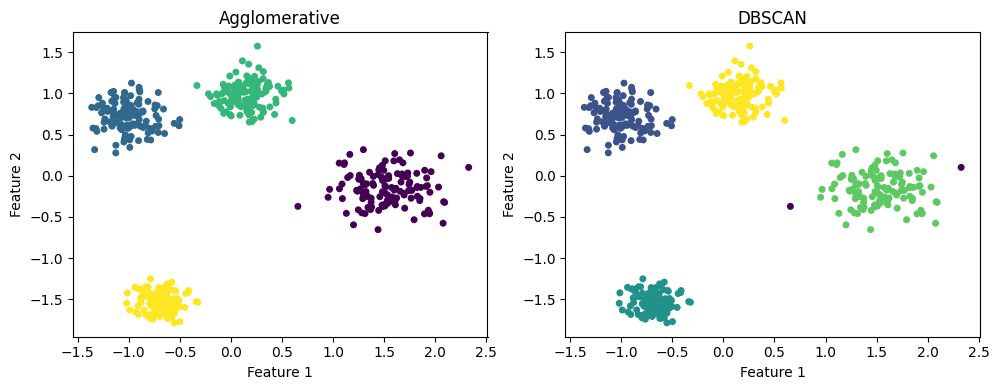

In [3]:

agg=AgglomerativeClustering(n_clusters=4).fit_predict(X_scaled)
db=DBSCAN(eps=.3,min_samples=8).fit_predict(X_scaled)
print("Agglomerative silhouette:",round(silhouette_score(X_scaled,agg),3))
print("DBSCAN labels (-1 means noise):",np.unique(db))
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].scatter(X_scaled[:,0],X_scaled[:,1],c=agg,s=16); axes[0].set_title("Agglomerative")
axes[1].scatter(X_scaled[:,0],X_scaled[:,1],c=db,s=16); axes[1].set_title("DBSCAN")
for ax in axes: ax.set_xlabel("Feature 1"); ax.set_ylabel("Feature 2")
plt.tight_layout(); plt.show()


## Exercises
1. Change `n_clusters` and compare inertia and silhouette.
2. Change DBSCAN's `eps` and `min_samples`.
3. Apply DBSCAN to `make_moons` and compare with K-means.
4. Explain why scaling matters.

## Summary
K-means is effective for compact groups; agglomerative clustering creates hierarchical groupings; DBSCAN can find irregular dense regions and noise. Use multiple diagnostics.